In [1]:
# Prepare environment
from pathlib import Path
from scipy import stats
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
calflora_full = gpd.read_file(processed_fldr / "calflora_full_cleaned.gpkg")
fire_with_plants_joined = gpd.read_file(processed_fldr / "fire_with_plants_joined.gpkg")
invasives_within_year = gpd.read_file(processed_fldr / "invasives_within_year.gpkg")

calflora_full = gpd.GeoDataFrame(
    calflora_full,
    geometry="geometry",
    crs="EPSG:3310"
)

fire_with_plants_joined = gpd.GeoDataFrame(
    fire_with_plants_joined,
    geometry="geometry",
    crs="EPSG:3310"
)

invasives_within_year = gpd.GeoDataFrame(
    invasives_within_year,
    geometry="geometry",
    crs="EPSG:3310"
)

In [2]:
# Find invasive species outside of fire polygons using left join
# Create a dataframe where all calflora observations will either have a prescribed fire data associated with it
# or be labeled NA
invasives_all = gpd.sjoin(
    left_df = calflora_full,
    right_df = prescribed_burns_cleaned,
    predicate = 'intersects',
    how = 'left'
)

# Label whether the observations occured before, after, or during a prescribed burn
# If there is no data, label observation as unknown
invasives_all["before_after"] = np.select(
    [
        (invasives_all["date"] < invasives_all["start_date"]),
        (invasives_all["date"] > invasives_all["end_date"]),
        (invasives_all["date"] > invasives_all["start_date"]) &
        (invasives_all["date"] < invasives_all["end_date"])
    ],
    ["before", "after", "during"],
    default="unknown"
)

# Create a new column called burned, if observation occurred before or after a burn, label it 1
invasives_all["burned"] = 0
invasives_all.loc[
    invasives_all["before_after"] == "after", "burned"
] = 1

# Check for duplicates
invasives_all.duplicated().sum()

# View invasives data
invasives_all.head()


,id,common_name,scientific_name,date,latitude,longitude,year_left,geometry,index_right,year_right,...,treatment_type,start_date,end_date,acres_treated,gis_acres_treated,Shape_Length,Shape_Area,duration_days,before_after,burned
0,mu66573,Tree tobacco,Nicotiana glauca,2026-11-01,37.579008,-121.691950,2026,POINT (-149207.832 -47288.114),NaN,NaN,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,unknown,0
1,mu66568,Many flowered tobacco,Nicotiana acuminata var. multiflora,2026-11-01,37.579016,-121.691945,2026,POINT (-149207.375 -47287.232),NaN,NaN,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,unknown,0
2,mg332097,Woolly mullein,Verbascum thapsus,2026-11-01,39.988915,-121.541723,2026,POINT (-131605.561 220296.985),NaN,NaN,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,unknown,0
3,io201270,Chinese banyan,Ficus microcarpa,2026-11-01,33.650913,-117.859695,2026,POINT (198588.698 -482639.186),NaN,NaN,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,unknown,0
4,io201269,NaN,Ficus rubiginosa,2026-11-01,33.650963,-117.860108,2026,POINT (198550.26 -482634.509),NaN,NaN,...,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,unknown,0


In [3]:
# Select columns on interest and create a cleaned dataframe
invasives_all_cleaned = (
    invasives_all
    .loc[:, ["common_name", "scientific_name", "date", "latitude", "longitude", "year_left", "geometry", "burned"]]
    .rename(columns= {
        "year_left" : "year"
    })
)

invasives_all_cleaned.head()

,common_name,scientific_name,date,latitude,longitude,year,geometry,burned
0,Tree tobacco,Nicotiana glauca,2026-11-01,37.579008,-121.691950,2026,POINT (-149207.832 -47288.114),0
1,Many flowered tobacco,Nicotiana acuminata var. multiflora,2026-11-01,37.579016,-121.691945,2026,POINT (-149207.375 -47287.232),0
2,Woolly mullein,Verbascum thapsus,2026-11-01,39.988915,-121.541723,2026,POINT (-131605.561 220296.985),0
3,Chinese banyan,Ficus microcarpa,2026-11-01,33.650913,-117.859695,2026,POINT (198588.698 -482639.186),0
4,NaN,Ficus rubiginosa,2026-11-01,33.650963,-117.860108,2026,POINT (198550.26 -482634.509),0


In [4]:
# Summarize invasive species observations by year
invasives_annual = (
    invasives_all_cleaned
    .groupby(["common_name", "year", "burned"])
    .agg(
        count = ("common_name", "size"),
    )
    .reset_index()
)

# Pivot invasives_annual to see how observations change each year by species
invasives_stats = (
    invasives_annual
    .pivot_table(
        index = ["common_name", "burned"],
        columns = "year",
        values = "count"
    )
    .fillna(0)
    .reset_index()
)

In [5]:
# View pivot table
invasives_stats.head()

year,common_name,burned,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,Aaron's beard,0,1.0,1.0,6.0,2.0,1.0,5.0,4.0,8.0,2.0,2.0,0.0
1,Aaron's beard,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Afghan pine,0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
3,African asparagus fern,0,28.0,52.0,18.0,56.0,56.0,64.0,49.0,28.0,34.0,35.0,37.0
4,African bermuda grass,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0


In [6]:
# Prepare a dataframe to run regressions on
invasives_regression = (
    invasives_all_cleaned
    .groupby(["common_name", "burned", "year"])
    .size()
    .reset_index(name="count")
)

In [7]:
# View dataframe used for regression
invasives_regression.head()

,common_name,burned,year,count
0,Aaron's beard,0,2016,1
1,Aaron's beard,0,2017,1
2,Aaron's beard,0,2018,6
3,Aaron's beard,0,2019,2
4,Aaron's beard,0,2020,1


In [8]:
# AI used to determine how to only use rows with 2+ observations
def run_regression(group):
    if group["year"].nunique() < 2:
        return pd.Series({"slope": np.nan, "intercept": np.nan})

    slope, intercept = np.polyfit(group["year"], group["count"], 1)

    return pd.Series({
        "slope": slope,
        "intercept": intercept
    })

species_regressions = (
    invasives_regression
    .groupby(["common_name", "burned"])
    .apply(run_regression)
    .reset_index()
    .loc[lambda df:df["slope"].notna()]
)

In [9]:
# View regression table with outputs
species_regressions

,common_name,burned,slope,intercept
0,Aaron's beard,0,2.181818e-01,-437.636364
2,Afghan pine,0,1.560582e-16,1.000000
3,African asparagus fern,0,-3.454545e-01,739.709091
6,African cornlily,0,4.061388e-17,1.000000
7,African daisy,0,-8.218085e-01,1664.452128
...,...,...,...,...
1517,hairy abutilon,0,4.615385e-01,-932.000000
1518,herb Robert,0,-1.145455e+00,2328.781818
1519,little Robin,0,-1.000000e-01,208.463636
1521,rosemary grevillea,0,2.818182e-01,-561.190909


In [10]:
# Group regression statistics by prescribed fire observations and non-prescribed fire observations
species_regressions.groupby("burned")["slope"].describe()

,count,mean,std,min,25%,50%,75%,max
burned,,,,,,,,
0,1066.0,0.057172,39.163604,-343.927273,-3.250000e-01,-1.659479e-17,0.179643,1202.000000
1,79.0,0.660911,3.603421,-7.500000,-1.987670e-16,3.764177e-17,0.500000,21.057325


In [11]:
# Summarize percent changes in invasive species observations each year for prescribed burn areas
# and non prescribed burn areas
species_regressions.groupby("burned")["slope"].agg(
    percent_increasing=lambda x: (x > 0).mean() * 100,
    percent_decreasing=lambda x: (x < 0).mean() * 100
)

,percent_increasing,percent_decreasing
burned,,
0,46.716698,53.001876
1,58.227848,41.772152


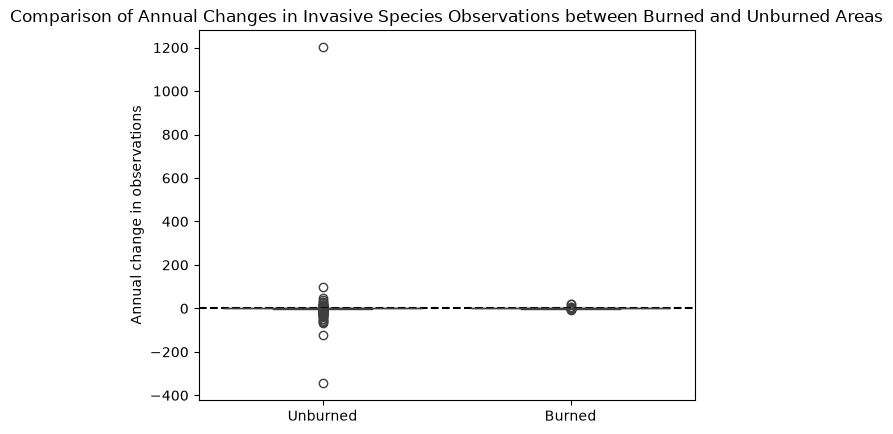

In [12]:
# Plot a boxplot of changes in invasive species observations between burned and unburned areas
sns.boxplot(data=species_regressions, x="burned", y="slope")
plt.title("Comparison of Annual Changes in Invasive Species Observations between Burned and Unburned Areas")
plt.xticks([0, 1], ["Unburned", "Burned"])
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Annual change in observations")
plt.xlabel("");

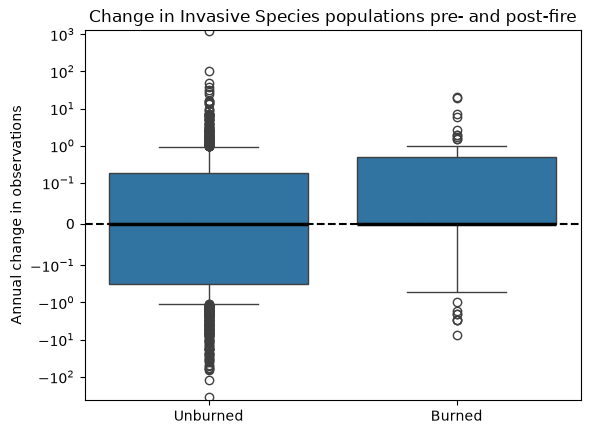

In [13]:
# Plot a boxplot of changes in invasive species observations pre- and post prescribed fire
fig, ax = plt.subplots()

sns.boxplot(data=species_regressions, x="burned", y="slope", ax=ax,
                medianprops={"color": "black", "linewidth": 2.5}
)

ax.set_yscale("symlog", linthresh=0.1)
ax.axhline(0, color="black", linestyle="--")
ax.set_xticks([0, 1], ["Unburned", "Burned"])

plt.title("Change in Invasive Species populations pre- and post-fire");
plt.xlabel("");
plt.ylabel("Annual change in observations");

In [14]:
# Find which species occur in both unburned and burned regions
# Divide regression dataframe into one with observations in prescribed fire areas and one outside of
# prescribed fire areas
species_regressions_in_fire = species_regressions[species_regressions["burned"] == 1]
species_regression_out_fire = species_regressions[species_regressions["burned"] == 0]

# Find list of species within each data set
in_fire_species = species_regressions_in_fire["common_name"]
out_fire_species = species_regression_out_fire["common_name"]

# Find list of species that occur in both unburned and burned regions
shared_species = list(set(in_fire_species) & set(out_fire_species))

In [15]:
# Filter both regression dataframes to only include species in the shared species list
filtered_species_regressions_in_fire = species_regressions_in_fire[species_regressions_in_fire["common_name"].isin(shared_species)]
filtered_species_regressions_out_fire = species_regression_out_fire[species_regression_out_fire["common_name"].isin(shared_species)]

In [16]:
# Run an indep two-sample t-test between the species regressions within fire areas and outside of fire areas
in_fire = filtered_species_regressions_in_fire["slope"]
out_fire = filtered_species_regressions_out_fire["slope"]

# Used AI assistance to find code on running a t-test in python
t_stat, p_val = stats.ttest_ind(in_fire, out_fire, equal_var=True)

print(f"t-statistic: {t_stat:.4f}, p_value: {p_val:.4f}")

t-statistic: 2.2986, p_value: 0.0229


In [17]:
#Full shared species
full_shared_species = pd.concat([filtered_species_regressions_in_fire, filtered_species_regressions_out_fire])

full_shared_species.groupby("burned")["slope"].describe()

,count,mean,std,min,25%,50%,75%,max
burned,,,,,,,,
0,79.0,-5.038784,21.743391,-124.209091,-6.818182e+00,-8.363636e-01,0.64697,100.272727
1,79.0,0.660911,3.603421,-7.500000,-1.987670e-16,3.764177e-17,0.50000,21.057325


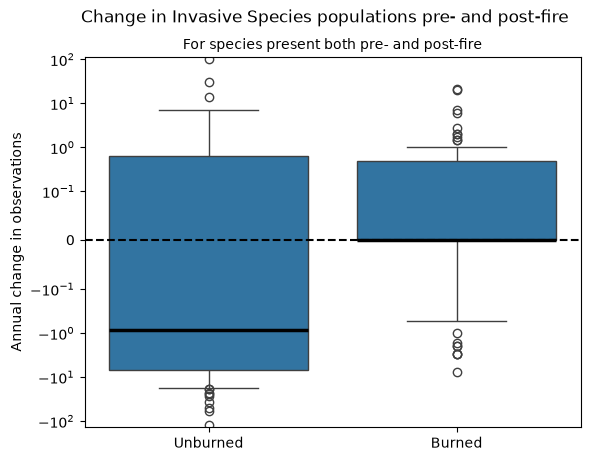

In [18]:
# Plot a boxplot of changes in invasive species with observations pre- and post prescribed fire
fig, ax = plt.subplots()

sns.boxplot(data=full_shared_species, x="burned", y="slope", ax=ax, medianprops={"color": "black", "linewidth": 2.5})

ax.set_yscale("symlog", linthresh=0.1)
ax.axhline(0, color="black", linestyle="--")
ax.set_xticks([0, 1], ["Unburned", "Burned"])

plt.suptitle("Change in Invasive Species populations pre- and post-fire");
plt.title("For species present both pre- and post-fire", fontsize = 10)
plt.xlabel("");
plt.ylabel("Annual change in observations");